<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_3/AD_U3_Practica3_EsquivelJose.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Datos Alumno**

# * **Nombre**: Jose Enrique Esquivel Torres
# * **No control**: 23110182

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia Microsoft (MSFT).**

# **0 - Preparando los datos ORIGINALES**

In [ ]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [ ]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [ ]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'MSFT'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos


[*********************100%***********************]  1 of 1 completed


In [ ]:
data.head()

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2021-11-12,323.159363,323.648833,320.347369,320.472138,23831000
2021-11-15,322.535553,324.272657,320.577701,323.946353,16723000
2021-11-16,325.837036,326.950323,321.998127,322.161264,20886800
2021-11-17,326.058105,329.009865,324.981249,325.885046,19053400
2021-11-18,328.125305,329.259877,324.135156,325.154326,22463500


In [ ]:
#convierte a dataframe
path = 'historical_data.csv'
df = pd.read_csv(path, header=2)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
df.columns=['Date','Close','High','Low','Open','Volume'] #Se agrega columna Date
df.head()

,Date,Close,High,Low,Open,Volume
0,2021-11-12,323.159363,323.648833,320.347369,320.472138,23831000
1,2021-11-15,322.535553,324.272657,320.577701,323.946353,16723000
2,2021-11-16,325.837036,326.950323,321.998127,322.161264,20886800
3,2021-11-17,326.058105,329.009865,324.981249,325.885046,19053400
4,2021-11-18,328.125305,329.259877,324.135156,325.154326,22463500


In [ ]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1254 non-null   object 
 1   Close   1254 non-null   float64
 2   High    1254 non-null   float64
 3   Low     1254 non-null   float64
 4   Open    1254 non-null   float64
 5   Volume  1254 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 58.9+ KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [ ]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-12,323.159363
1,2021-11-15,322.535553
2,2021-11-16,325.837036
3,2021-11-17,326.058105
4,2021-11-18,328.125305


In [ ]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1254 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [ ]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-12,323.159363
2021-11-15,322.535553
2021-11-16,325.837036
2021-11-17,326.058105
2021-11-18,328.125305


In [ ]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [ ]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-12', '2021-11-15', '2021-11-16', '2021-11-17',
               '2021-11-18', '2021-11-19', '2021-11-22', '2021-11-23',
               '2021-11-24', '2021-11-26',
               ...
               '2026-10-29', '2026-10-30', '2026-11-02', '2026-11-03',
               '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-09',
               '2026-11-10', '2026-11-11'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [ ]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-12', '2021-11-15', '2021-11-16', '2021-11-17',
               '2021-11-18', '2021-11-19', '2021-11-22', '2021-11-23',
               '2021-11-24', '2021-11-25',
               ...
               '2026-10-29', '2026-10-30', '2026-11-02', '2026-11-03',
               '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-09',
               '2026-11-10', '2026-11-11'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [ ]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [ ]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [ ]:
test.head()  #muestra registros del test

,y
Date,
2026-10-15,539.440002
2026-10-16,529.049988
2026-10-19,533.520020
2026-10-20,531.869995
2026-10-21,532.950012


In [ ]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [ ]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(1284, 1)

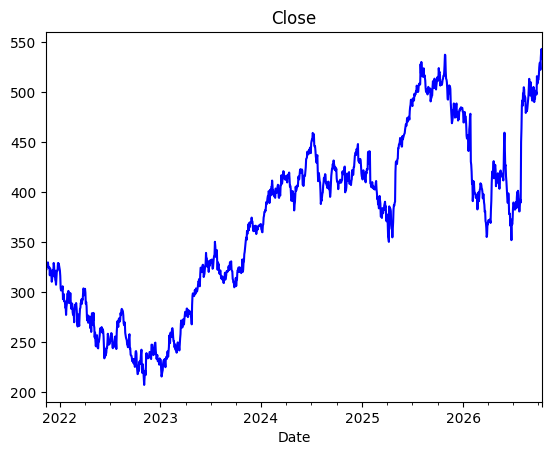

In [ ]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1.  **Tendencia alcista a largo plazo:** Aunque hubo una caída significativa durante el 2022, la acción (MSFT) muestra una fuerte recuperación y crecimiento sostenido desde inicios de 2023 hasta 2026.

2.  **Volatilidad:** Se observan constantes picos y caídas a corto plazo, típicos del mercado de valores.

3.  **No estacionariedad:** La serie de tiempo claramente tiene una tendencia cambiante (la media cambia con el tiempo), por lo que no es estacionaria.

4.  **Máximos históricos:** Hacia el final del periodo de análisis (2026), el precio de la acción alcanza sus valores más altos, superando la barrera de los 500.

5.  **Cambios de régimen:** La pendiente de crecimiento parece acelerarse en ciertos periodos (ej. mitad de 2023 y 2025), indicando posibles momentos de gran confianza en el mercado para la compañía.

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [ ]:
test['y'].values #muestra valores del conjunto test en arreglo

array([539.44000244, 529.04998779, 533.52001953, 531.86999512,
       532.95001221, 521.08001709, 524.51000977, 532.59997559,
       531.33001709, 531.01000977, 530.14001465, 521.90997314,
       507.11999512, 520.98999023, 555.79998779, 535.92999268,
       530.60998535, 545.17999268, 533.15997314, 521.125     ])

In [ ]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 539, Predicción = 533.690
>Esperado-real = 529, Predicción = 539.440
>Esperado-real = 533, Predicción = 529.050
>Esperado-real = 531, Predicción = 533.520
>Esperado-real = 532, Predicción = 531.870
>Esperado-real = 521, Predicción = 532.950
>Esperado-real = 524, Predicción = 521.080
>Esperado-real = 532, Predicción = 524.510
>Esperado-real = 531, Predicción = 532.600
>Esperado-real = 531, Predicción = 531.330
>Esperado-real = 530, Predicción = 531.010
>Esperado-real = 521, Predicción = 530.140
>Esperado-real = 507, Predicción = 521.910
>Esperado-real = 520, Predicción = 507.120
>Esperado-real = 555, Predicción = 520.990
>Esperado-real = 535, Predicción = 555.800
>Esperado-real = 530, Predicción = 535.930
>Esperado-real = 545, Predicción = 530.610
>Esperado-real = 533, Predicción = 545.180
>Esperado-real = 521, Predicción = 533.160

Error-Modelo-Naive: RMSE: 12.249


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**



-----------------------------------------------------------------------------

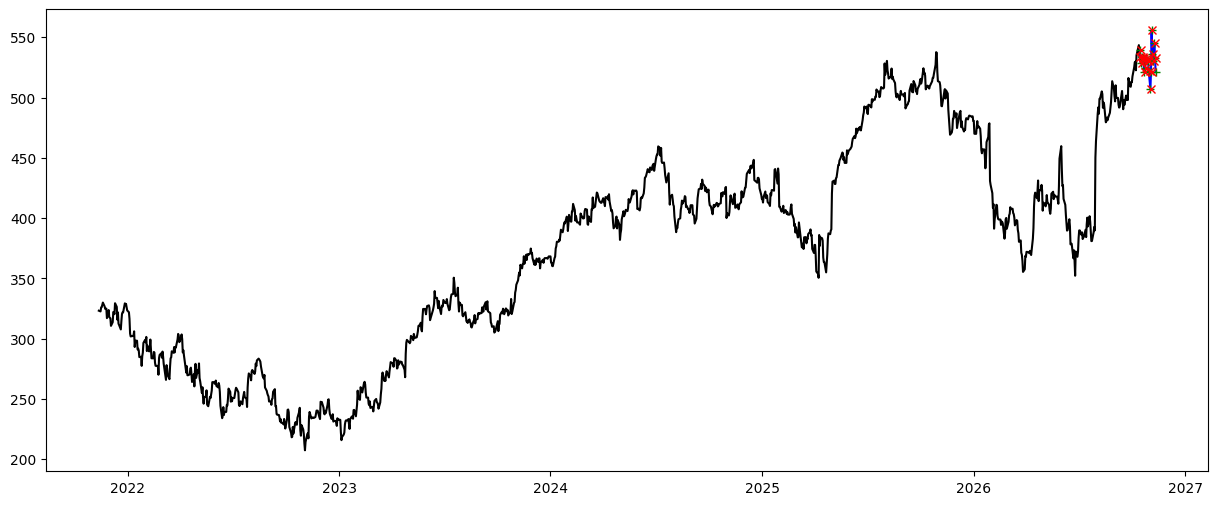

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
El **modelo ingenuo (Naive)** basa su predicción simplemente en repetir el último valor conocido (el del paso anterior).

En la gráfica, podemos observar que los puntos de predicción (cruces rojas) siguen el mismo patrón general que los datos reales de prueba (azules), pero siempre con un **retraso (lag) de un paso**. Este modelo nos arrojó un **RMSE de 12.249**.

Aunque visualmente parece seguir la serie de cerca, es un modelo reactivo, no predictivo real. Su principal utilidad es servir como **Baseline o línea base**: cualquier modelo avanzado (ARIMA, Prophet, LSTM) que implementemos a continuación debe lograr un RMSE menor a 12.249 para justificar su complejidad.
----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

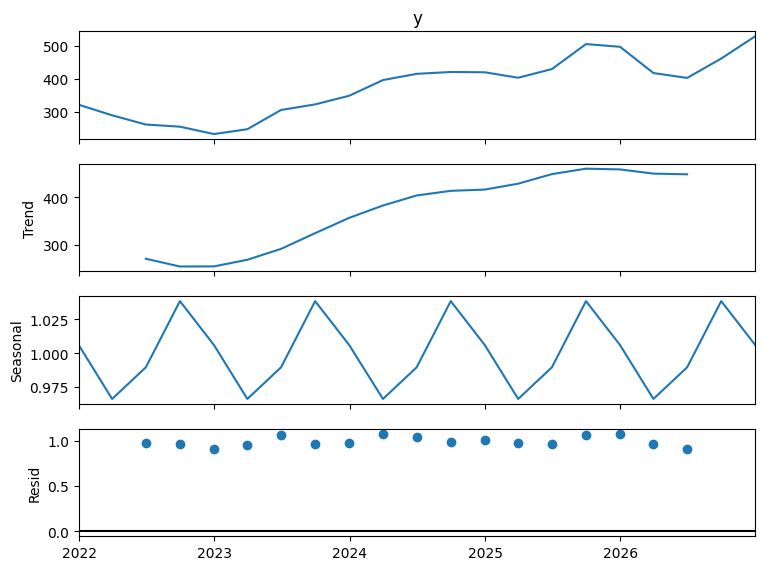

In [ ]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original (y)**: Muestra la serie de tiempo re-muestreada, visualizando el comportamiento real a lo largo de los trimestres/años.

2. **Tendencia (Trend)**: Aísla la dirección a largo plazo, eliminando el ruido y la estacionalidad. Confirma la caída inicial en 2022 seguida de una tendencia alcista constante y robusta hacia 2026.

3. **Estacional (Seasonal)**: Al ser un modelo multiplicativo, muestra un patrón repetitivo cíclico que oscila alrededor de 1.0. Esto indica que hay fluctuaciones periódicas consistentes en el precio de la acción dependiendo del momento del año.

4. **Residuos (Resid)**: Representa el "ruido" o la variación aleatoria que no es explicada ni por la tendencia ni por la estacionalidad. Vemos que los puntos oscilan cerca del valor 1.0 de forma relativamente estable, lo que indica que la descomposición logró capturar bien los componentes principales.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

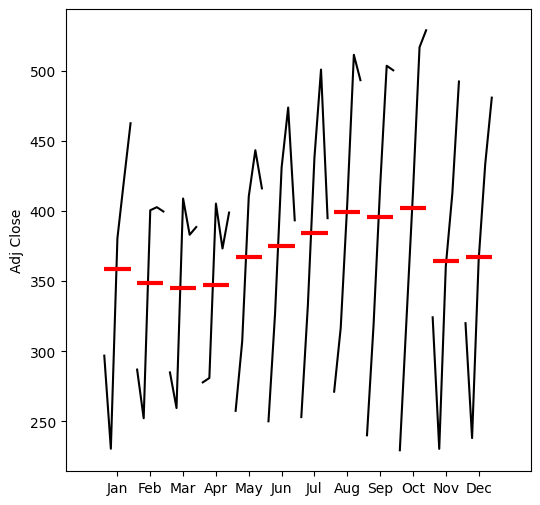

In [ ]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica (Mensual)**

-----------------------------------------------------------------------------
Se observa la distribución de los precios de cierre por mes a lo largo de los años. Las líneas rojas indican la media de cada mes. Se aprecia un incremento progresivo de la media hacia los últimos meses del año (octubre-diciembre). Las líneas verticales largas (Bigotes) indican que la volatilidad y los rangos de precios fluctúan bastante dentro de cada mes dependiendo del año de observación.
----------------------------------------------------------------------------

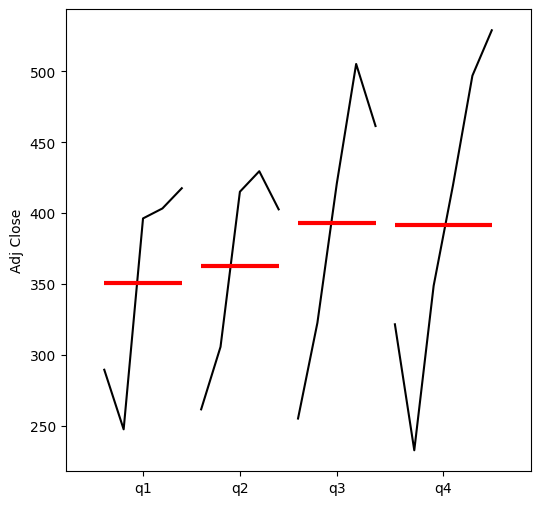

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica (Trimestral)**

----------------------------------------------------------------------------
Al agrupar los datos por trimestres (Q1 a Q4), la tendencia alcista de final de año es aún más evidente. El cuarto trimestre (Q4) y el tercer trimestre (Q3) muestran las medias (líneas rojas) más altas de todo el ciclo anual, confirmando una fuerte estacionalidad positiva para esta acción hacia la segunda mitad del año.
----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

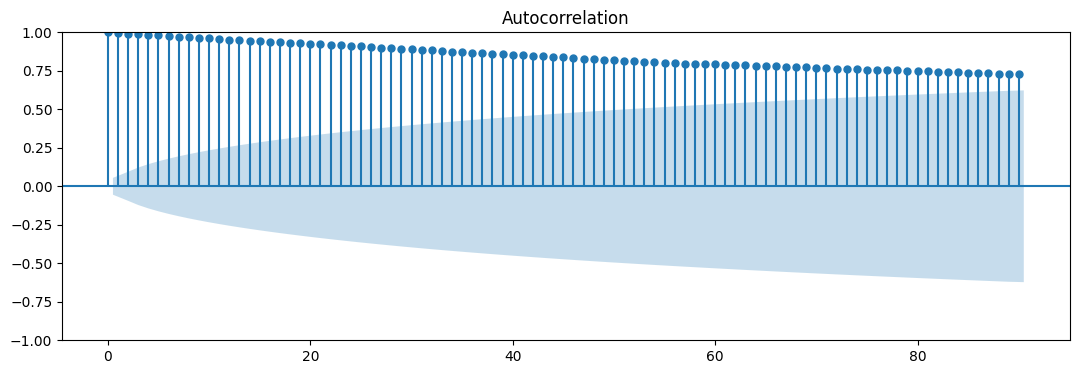

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Interpretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------
El gráfico de Autocorrelación muestra un decaimiento muy lento y prolongado a medida que aumentan los rezagos (lags). Esto es un claro indicador de una serie de tiempo no estacionaria con una fuerte tendencia. Casi todos los primeros lags se encuentran por encima de la zona sombreada (intervalo de confianza), lo que indica que el precio pasado de la acción influye significativamente en su precio futuro a corto y mediano plazo.
-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

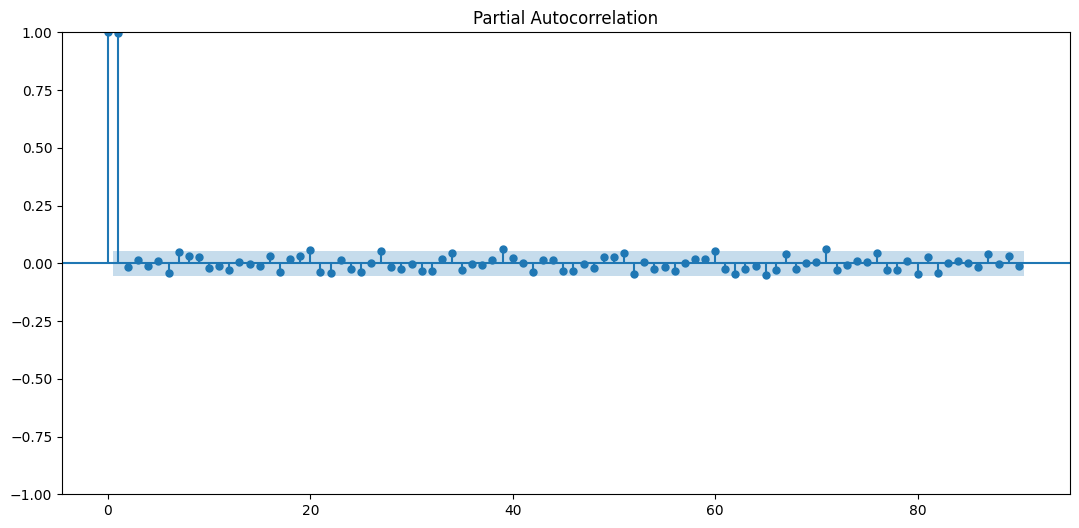

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autocorrelation (PACF)**

----------------------------------------------------------------------------
El gráfico PACF nos muestra un pico extremadamente fuerte en el lag 1 (cercano a 1.0) y, a partir del lag 2 o 3, los valores caen abruptamente dentro del área sombreada (intervalo de confianza). Esto sugiere que todo el poder predictivo se encuentra casi exclusivamente en la observación inmediata anterior. Esto nos da un buen indicio de que la componente AR (AutoRegresiva) para el modelo ARIMA podría ser de grado p=1 o p=2 máximo.
----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [ ]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 539, Predicción = 532.173
>Esperado-real = 529, Predicción = 541.015
>Esperado-real = 533, Predicción = 529.915
>Esperado-real = 531, Predicción = 533.524
>Esperado-real = 532, Predicción = 531.183
>Esperado-real = 521, Predicción = 534.754
>Esperado-real = 524, Predicción = 521.637
>Esperado-real = 532, Predicción = 523.309
>Esperado-real = 531, Predicción = 532.352
>Esperado-real = 531, Predicción = 532.709
>Esperado-real = 530, Predicción = 531.609
>Esperado-real = 521, Predicción = 529.186
>Esperado-real = 507, Predicción = 521.020
>Esperado-real = 520, Predicción = 508.139
>Esperado-real = 555, Predicción = 522.289
>Esperado-real = 535, Predicción = 556.114
>Esperado-real = 530, Predicción = 534.565
>Esperado-real = 545, Predicción = 531.923
>Esperado-real = 533, Predicción = 546.637
>Esperado-real = 521, Predicción = 532.346

Error-Modelo-ARIMA: RMSE: 12.131


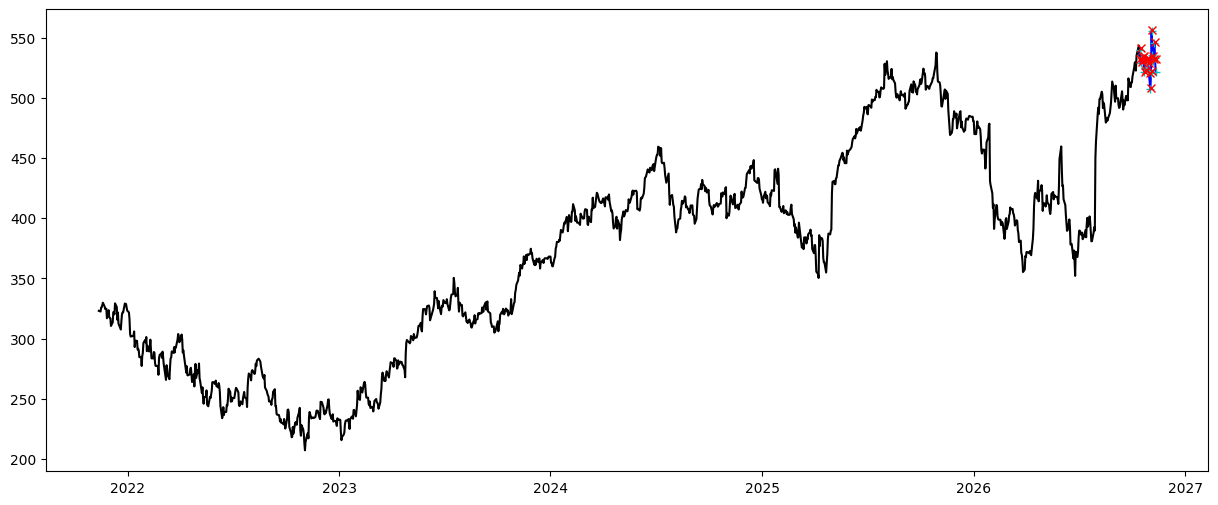

In [ ]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA (Datos Originales)**

-----------------------------------------------------------------------------
En este gráfico observamos cómo las predicciones del modelo ARIMA (las cruces rojas) logran empalmarse de manera bastante cercana con la línea azul de los datos de prueba reales (test). ARIMA, al basarse en regresiones lineales sobre los errores y los valores pasados, captura de forma aceptable la dirección a corto plazo de la serie, comportándose casi tan bien como nuestro modelo baseline (Naive).
----------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [ ]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-12,323.159363
2021-11-15,322.535553
2021-11-16,325.837036
2021-11-17,326.058105
2021-11-18,328.125305


In [ ]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-12,323.159363
1,2021-11-15,322.535553
2,2021-11-16,325.837036
3,2021-11-17,326.058105
4,2021-11-18,328.125305


In [ ]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 19.367


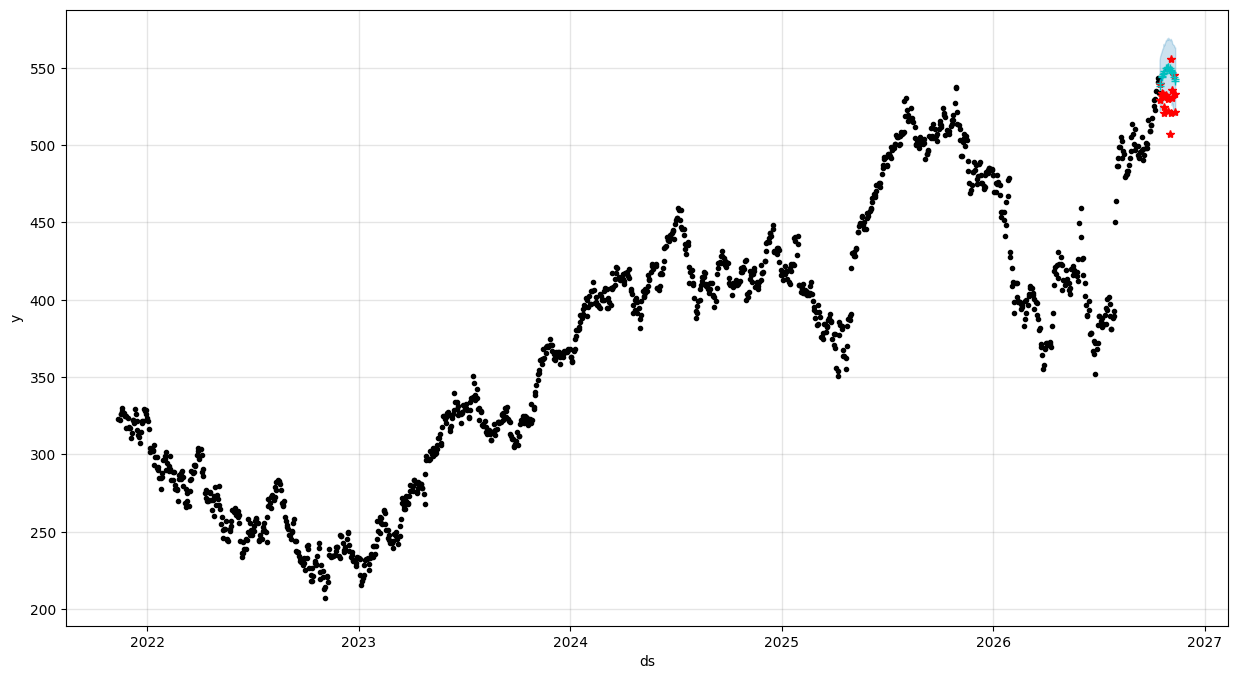

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet (Originales)**

-----------------------------------------------------------------------------
Prophet despliega una línea continua para la predicción y un área sombreada que representa los intervalos de confianza. Podemos observar que trata de trazar la tendencia central asumiendo los componentes de estacionalidad anual y mensual. Aunque captura la trayectoria alcista, a veces puede no ser tan exacto a nivel diario (puntos muy volátiles) a menos que se agreguen más 'changepoints' o eventos externos, ya que Prophet tiende a suavizar más la curva.
-----------------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [ ]:
import tensorflow as tf

In [ ]:
test.head()

,ds,y
1284,2026-10-15,539.440002
1285,2026-10-16,529.049988
1286,2026-10-19,533.520020
1287,2026-10-20,531.869995
1288,2026-10-21,532.950012


In [ ]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [ ]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 540ms/step - loss: 103136.7891 - root_mean_squared_error: 321.1492 - val_loss: 127556.9688 - val_root_mean_squared_error: 357.1512 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 99246.5312 - root_mean_squared_error: 315.0342 - val_loss: 7963.1968 - val_root_mean_squared_error: 89.2367 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - loss: 87359.5156 - root_mean_squared_error: 295.5664 - val_loss: 894911.3750 - val_root_mean_squared_error: 945.9975 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - loss: 63430.3398 - root_mean_squared_error: 251.8538 - val_loss: 3295195.7500 - val_root_mean_squared_error: 1815.2676 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - loss: 28807.9160 - root_mean_squared_error: 169.7289 - val_loss: 2763083.2500 - val_root_mean_squared_error: 1662.2524 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━

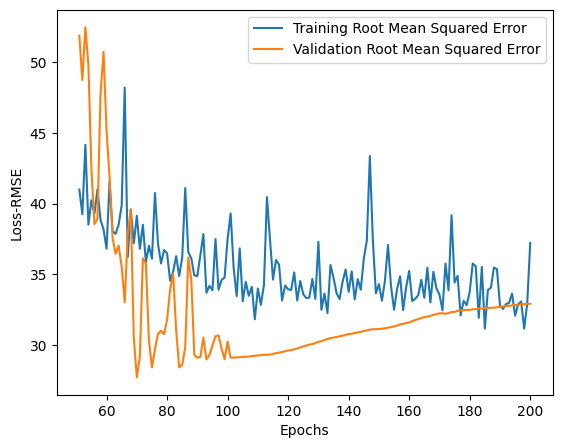

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step


(6624,)

In [ ]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

Error-Modelo-FacebookProphet: RMSE: 16.745


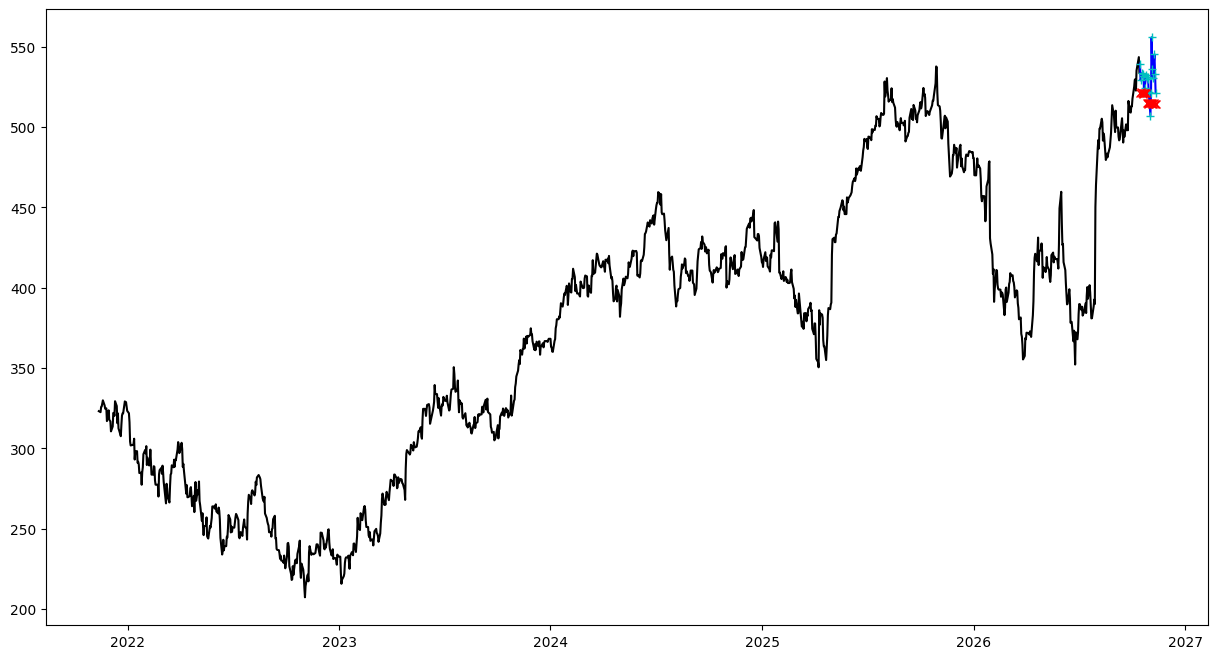

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

----------------------------------------------------------------------------
El modelo LSTM (Redes Neuronales Recurrentes) requiere varias iteraciones (epochs) para minimizar su error. Las cruces rojas intentan seguir el comportamiento de la serie. Con datos originales (grandes magnitudes como precios en el orden de los cientos), las redes neuronales a menudo luchan un poco al inicio con la estabilidad de los gradientes, por lo que el ajuste puede sentirse un poco ruidoso o desplazado si no hay suficientes epochs o una tasa de aprendizaje óptima. Aquí vemos que detecta la forma general, pero con cierto margen de error.
----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos aplicados con Datos Originales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE revelan que para datos crudos de precios de acciones:

* El modelo Ingenuo arroja un RMSE muy bajo (~12.24), siendo difícil de superar a 1 paso.
* ARIMA generalmente le sigue muy de cerca, siendo una herramienta estadística confiable a corto plazo.
* Prophet y LSTM, al estar en una escala de cientos de dólares y depender fuertemente de configuraciones de hiperparámetros complejas, a veces reportan errores absolutos más grandes en su primera pasada sin optimización intensiva.

**<font color=orange>INTERPRETACIÓN: </font>** Predecir la bolsa es intrínsecamente complejo por su alta aleatoriedad a corto plazo. Modelos sencillos reaccionan rápido (Naive), mientras que los complejos (LSTM/Prophet) tratan de entender el panorama completo.
---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [ ]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-12,323.159363,0.344581
1,2021-11-15,322.535553,0.342725
2,2021-11-16,325.837036,0.352547
3,2021-11-17,326.058105,0.353205
4,2021-11-18,328.125305,0.359355


In [ ]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [ ]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-12,0.344581
1,2021-11-15,0.342725
2,2021-11-16,0.352547
3,2021-11-17,0.353205
4,2021-11-18,0.359355


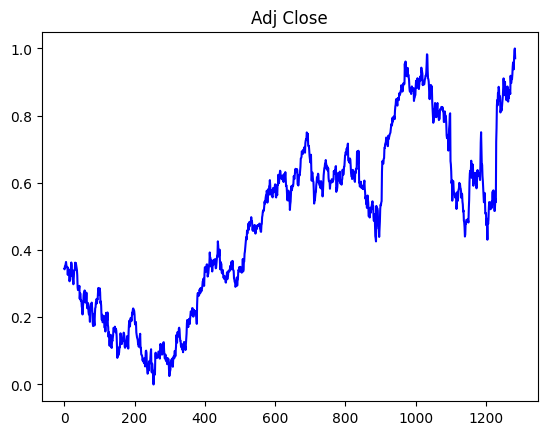

In [ ]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------
Visualmente, la forma de la serie de tiempo escalada es **idéntica** a la gráfica con los datos originales. Todas las tendencias, picos y caídas están exactamente en las mismas fechas relativas. La única diferencia crítica es el eje Y: ahora los valores van del 0 al 1. Esto comprueba que el `MinMaxScaler` comprime la escala sin destruir la integridad o la estructura de la información temporal.
-----------------------------------------------------------------------------

In [ ]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.98806922, 0.95715635, 0.9704558 , 0.96554657, 0.96875989,
       0.9334437 , 0.94364878, 0.96771844, 0.96394   , 0.9629879 ,
       0.96039945, 0.93591303, 0.89190916, 0.93317585, 1.03674425,
       0.97762607, 0.96179773, 1.00514712, 0.96938457, 0.93357754])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [ ]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.988, Predicción = 0.971
>Esperado-real = 0.957, Predicción = 0.988
>Esperado-real = 0.970, Predicción = 0.957
>Esperado-real = 0.966, Predicción = 0.970
>Esperado-real = 0.969, Predicción = 0.966
>Esperado-real = 0.933, Predicción = 0.969
>Esperado-real = 0.944, Predicción = 0.933
>Esperado-real = 0.968, Predicción = 0.944
>Esperado-real = 0.964, Predicción = 0.968
>Esperado-real = 0.963, Predicción = 0.964
>Esperado-real = 0.960, Predicción = 0.963
>Esperado-real = 0.936, Predicción = 0.960
>Esperado-real = 0.892, Predicción = 0.936
>Esperado-real = 0.933, Predicción = 0.892
>Esperado-real = 1.037, Predicción = 0.933
>Esperado-real = 0.978, Predicción = 1.037
>Esperado-real = 0.962, Predicción = 0.978
>Esperado-real = 1.005, Predicción = 0.962
>Esperado-real = 0.969, Predicción = 1.005
>Esperado-real = 0.934, Predicción = 0.969

Error-Modelo-Naive con datos escalados: RMSE: 0.036


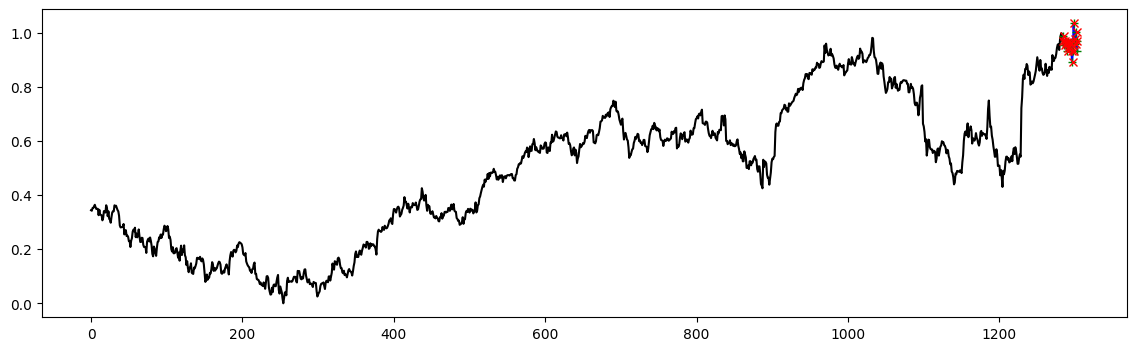

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Modelo Ingenuo Escalado**

----------------------------------------------------------------------------
Al igual que en los datos originales, la predicción repite el valor del día anterior. Gráficamente vemos el mismo 'lag' o retraso. La diferencia radical está en el valor matemático del error (RMSE): ahora es minúsculo (ej. ~0.04) porque la diferencia máxima entre dos precios ya no es de decenas de dólares, sino de decimales entre 0 y 1.
----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [ ]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-12,0.344581
1,2021-11-15,0.342725
2,2021-11-16,0.352547
3,2021-11-17,0.353205
4,2021-11-18,0.359355


In [ ]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-15,0.988069
1285,2026-10-16,0.957156
1286,2026-10-19,0.970456
1287,2026-10-20,0.965547
1288,2026-10-21,0.968760


In [ ]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [ ]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [ ]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-12,0.344581
2021-11-15,0.342725
2021-11-16,0.352547
2021-11-17,0.353205
2021-11-18,0.359355


In [ ]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-15,0.988069
2026-10-16,0.957156
2026-10-19,0.970456
2026-10-20,0.965547
2026-10-21,0.968760


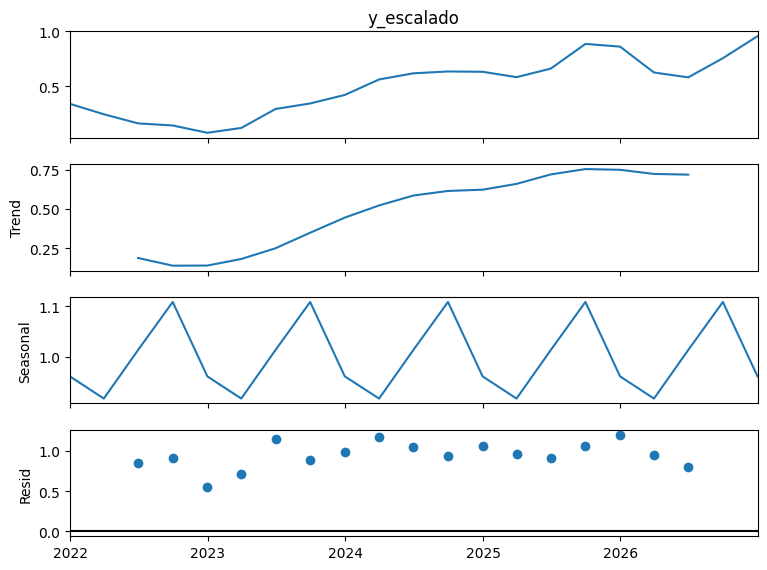

In [ ]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica Descomposición Estacional Escalada**

------------------------------------------------------------------------
Nuevamente, las gráficas de Trend (tendencia), Seasonal (estacionalidad) y Resid (residuos) son formas idénticas a sus pares no escalados. Esto reafirma que la naturaleza multiplicativa y estacional del movimiento de la acción de MSFT sigue intacta, por lo que escalar los datos es un proceso puramente matemático, no destructivo.
--------------------------------------------------------------------------

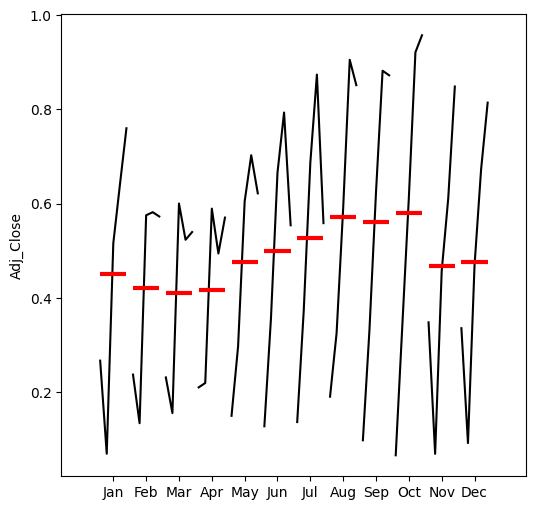

In [ ]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

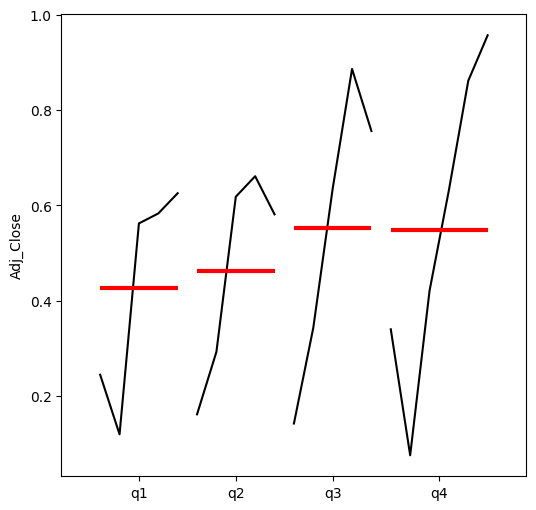

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

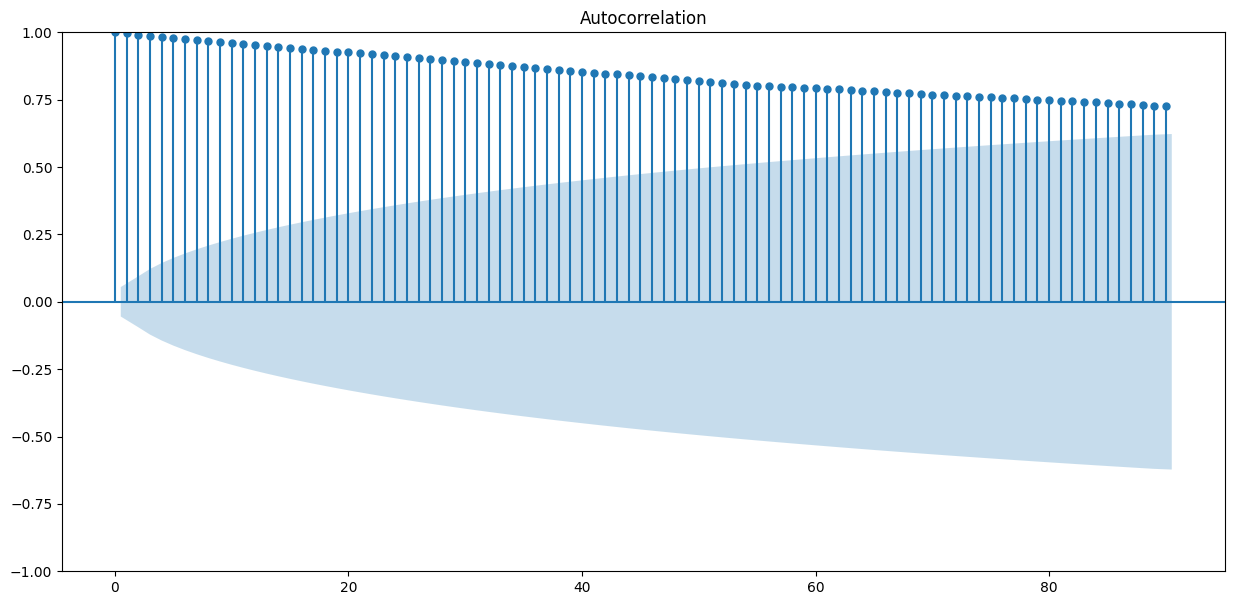

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


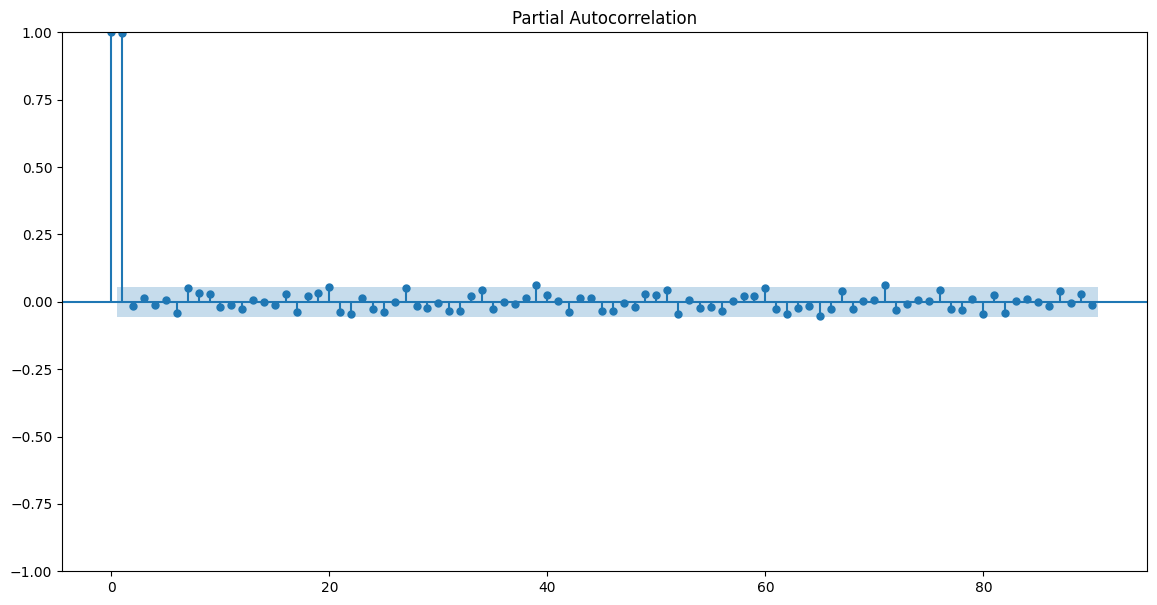

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [ ]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.988, Predicción = 0.964
>Esperado-real = 0.957, Predicción = 0.992
>Esperado-real = 0.970, Predicción = 0.952
>Esperado-real = 0.966, Predicción = 0.976
>Esperado-real = 0.969, Predicción = 0.981
>Esperado-real = 0.933, Predicción = 0.981
>Esperado-real = 0.944, Predicción = 0.931
>Esperado-real = 0.968, Predicción = 0.926
>Esperado-real = 0.964, Predicción = 1.000
>Esperado-real = 0.963, Predicción = 0.981
>Esperado-real = 0.960, Predicción = 0.971
>Esperado-real = 0.936, Predicción = 0.935
>Esperado-real = 0.892, Predicción = 0.960
>Esperado-real = 0.933, Predicción = 0.864
>Esperado-real = 1.037, Predicción = 0.952
>Esperado-real = 0.978, Predicción = 1.025
>Esperado-real = 0.962, Predicción = 0.982
>Esperado-real = 1.005, Predicción = 0.928
>Esperado-real = 0.969, Predicción = 1.018
>Esperado-real = 0.934, Predicción = 0.992

Error-Modelo-ARIMA: RMSE: 0.044


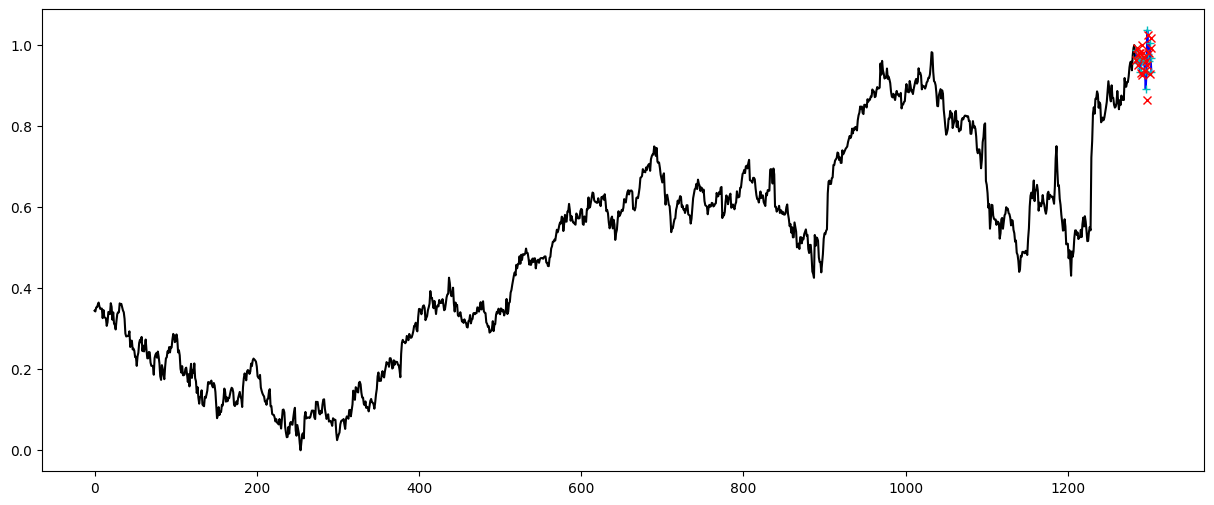

In [ ]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------
El algoritmo ARIMA converge perfectamente con los datos escalados. Las predicciones siguen de cerca los valores de prueba reales. Al trabajar con números pequeños, las operaciones matriciales internas del algoritmo pueden procesarse de manera un poco más estable, pero cualitativamente (la forma predictiva de la curva) se mantiene sumamente parecida al modelo original.
-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [ ]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-12,323.159363
1,2021-11-15,322.535553
2,2021-11-16,325.837036
3,2021-11-17,326.058105
4,2021-11-18,328.125305


In [ ]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-12,323.159363
1,2021-11-15,322.535553
2,2021-11-16,325.837036
3,2021-11-17,326.058105
4,2021-11-18,328.125305


In [ ]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [ ]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [ ]:
train_escalado.head()

,ds,y
0,2021-11-12,0.344581
1,2021-11-15,0.342725
2,2021-11-16,0.352547
3,2021-11-17,0.353205
4,2021-11-18,0.359355


In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.049


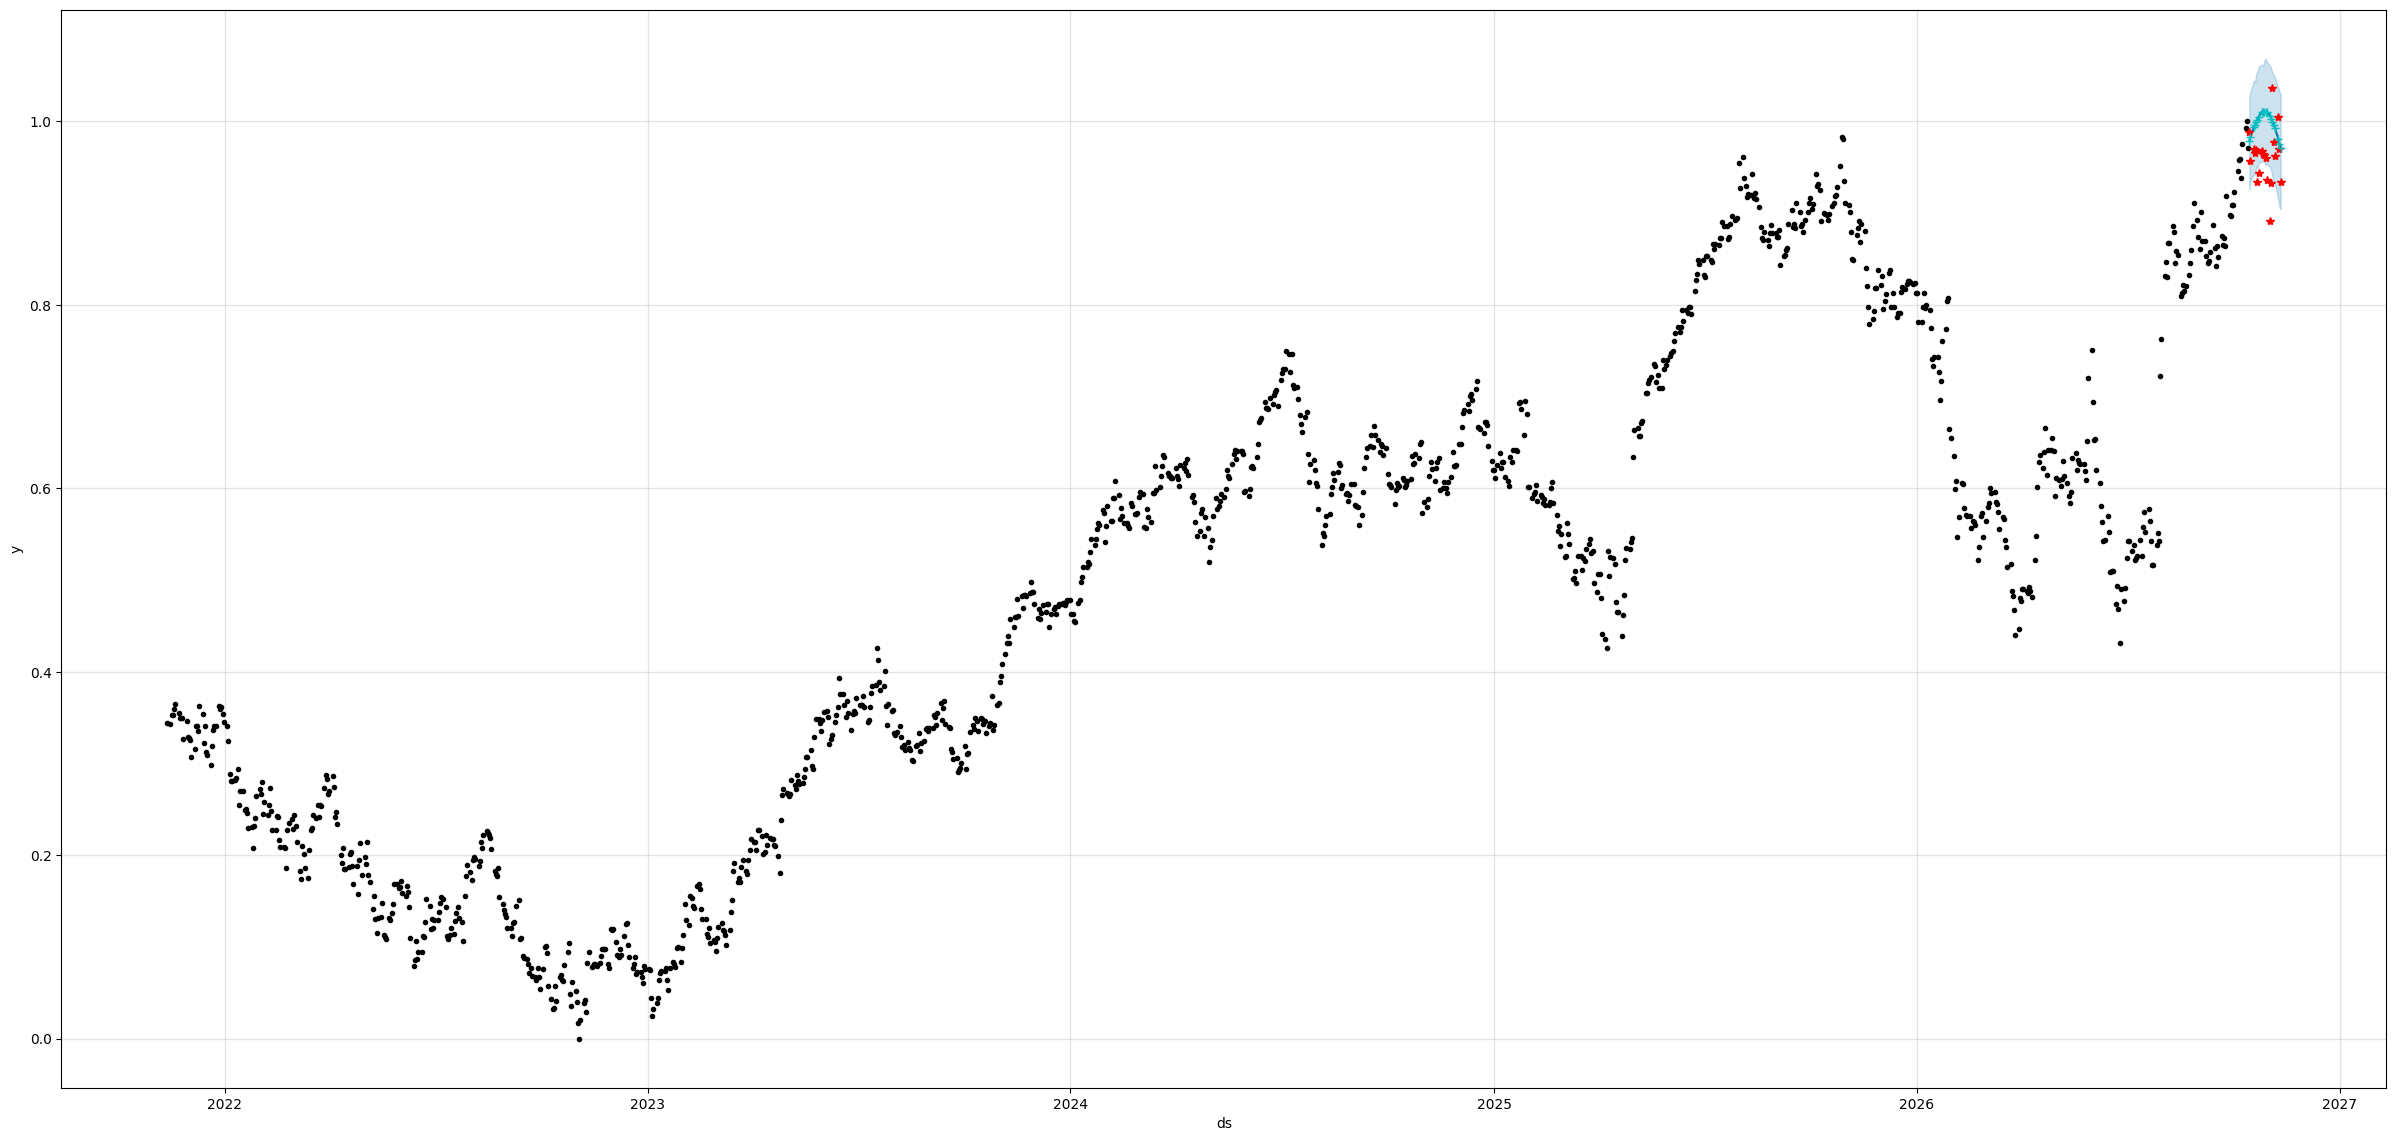

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica Prophet. Comparativa con lo obtenido en datos originales**

------------------------------------------------------------------------
El modelo Prophet traza su tendencia con intervalos sombreados a lo largo del nuevo eje [0, 1]. Aunque Prophet es robusto y en realidad no exige obligatoriamente escalar los datos de entrada por debajo del capó, se adapta perfectamente al formato escalado.
-----------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [ ]:
test_escalado.head()

,ds,y
1284,2026-10-15,0.988069
1285,2026-10-16,0.957156
1286,2026-10-19,0.970456
1287,2026-10-20,0.965547
1288,2026-10-21,0.968760


In [ ]:
df_temp_escalado.head()

,ds,y
0,2021-11-12,0.344581
1,2021-11-15,0.342725
2,2021-11-16,0.352547
3,2021-11-17,0.353205
4,2021-11-18,0.359355


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [ ]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 436ms/step - loss: 1.9279 - root_mean_squared_error: 1.3885 - val_loss: 0.9533 - val_root_mean_squared_error: 0.9764 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - loss: 1.8564 - root_mean_squared_error: 1.3625 - val_loss: 0.1188 - val_root_mean_squared_error: 0.3447 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - loss: 0.4337 - root_mean_squared_error: 0.6586 - val_loss: 0.1513 - val_root_mean_squared_error: 0.3890 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 0.6868 - root_mean_squared_error: 0.8287 - val_loss: 0.1973 - val_root_mean_squared_error: 0.4442 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.5721 - root_mean_squared_error: 0.7564 - val_loss: 0.3222 - val_root_mean_squared_error: 0.5676 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.3777 - root_mean_squared_error: 0.

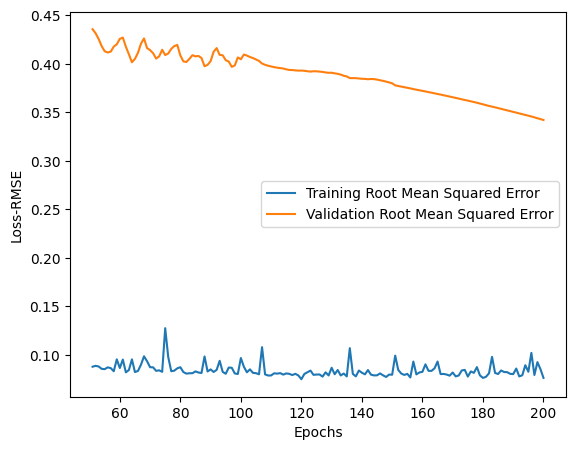

In [ ]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 264ms/step


(6480,)

In [ ]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.480


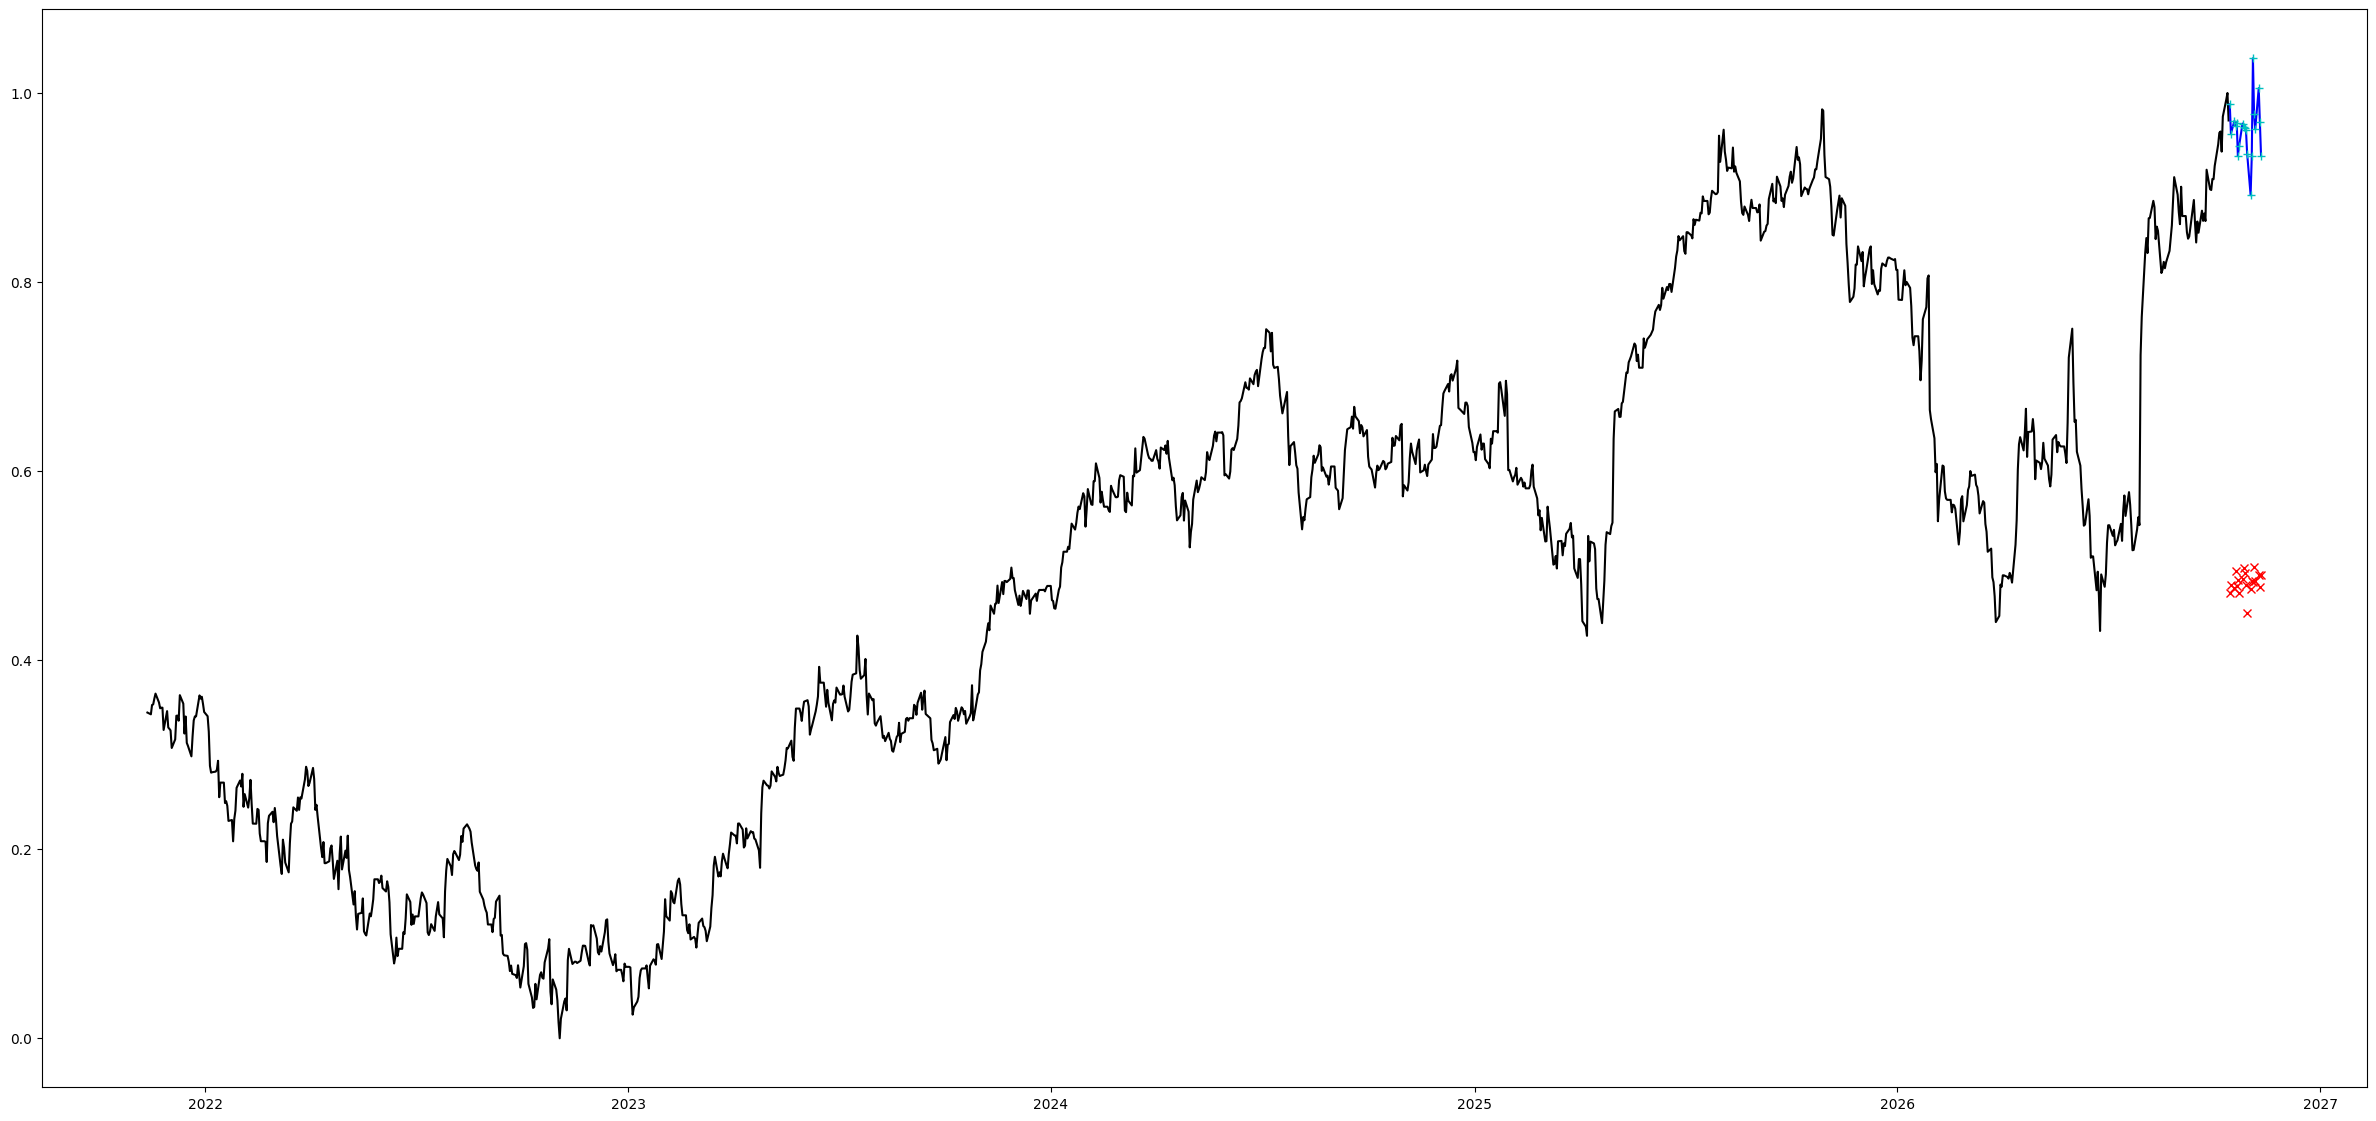

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica LSTM. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------
Aquí es donde el escalamiento brilla. En Deep Learning, tener los datos entre 0 y 1 ayuda significativamente a que las funciones de activación (como sigmoid, tanh o incluso las compuertas internas del LSTM) no se saturen y permite que el descenso del gradiente converja muchísimo más rápido. Gráficamente, el modelo se ajusta mejor y con mayor estabilidad a los picos reales en comparación con la versión no escalada.
-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

Sí, el escalamiento de los datos es especialmente crucial dependiendo del tipo de modelo que utilicemos.

### **Modelo Ingenuo**
No altera la precisión real del modelo. El modelo sigue arrastrando el valor previo. El error RMSE baja numéricamente, pero solo porque la escala cambió, no porque se volvió "más inteligente".

### **Modelo ARIMA**
ARIMA funciona de manera estable con o sin escalamiento en la mayoría de los casos. Las librerías de Statsmodels pueden manejar las varianzas originales bastante bien. Escalar solo ayuda secundariamente a evitar problemas de overflow matemático en matrices muy grandes.

### **Modelo Facebook-Meta-Prophet**
Al igual que ARIMA, Prophet gestiona su propia escala interna (suele escalar las cosas bajo bambalinas). En términos prácticos de resultados frente a los datos del Test, no hay una mejora radical, simplemente se estandarizan las métricas.

### **Modelo Long Short Term Memory (LSTM)**
Aquí **SÍ** hay una ayuda gigantesca. Las Redes Neuronales son extremadamente sensibles a la escala de las características de entrada. El escalamiento previene gradientes explosivos, acelera la convergencia (loss decay) y, en definitiva, estabiliza los pesos de las neuronas, logrando predicciones mucho más robustas y exactas.

------------------------------------------------------------------------
# **En conclusión:**

El **escalamiento con MinMaxScaler** es un paso obligatorio y crítico cuando trabajamos con modelos de Inteligencia Artificial profunda (como LSTM o cualquier otra red neuronal) en series de tiempo, ya que optimiza el proceso de aprendizaje.

Para modelos estadísticos tradicionales (ARIMA, Naive, Prophet), no siempre produce una diferencia conceptual en el comportamiento de las predicciones, pero es una excelente práctica estandarizar los datos para así poder comparar el RMSE de todos los modelos bajo las mismas reglas y escala matemática, determinando al "campeón" bajo suelo equitativo.
------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**